# TASK 2 - assignment 4: replicating SynthFair

Replication of Hattatoğlu, Qahtan, Kaya & Velegrakis, *SynthFair: Ensuring Subgroup Fairness in Classification via
Synthetic Data Generation* (CSCE 2024, CCIS 2253), on the three datasets in `datasets/`.

The authors' code is at [bendiste/Algorithmic-Fairness](https://github.com/bendiste/Algorithmic-Fairness). Their result
spreadsheets are copied to `authors_results/` (commit in `SOURCE_COMMIT.txt`). Their code was read but not imported or
run, because it needs pandas 1.x. Everything below is reimplemented.


## Findings

**The core SynthFair result replicates; the LFR and Adversarial Debiasing baselines do not.** Stra3 with RF raises DIR and lowers |EOD| on all three datasets, at a modest accuracy cost and close to the published values. All values below are means over 10 seeded repetitions.

| SynthFair (RF, Stra3) | German mine / paper | Adult mine / paper | COMPAS mine / paper |
|---|---|---|---|
| \|EOD\| | 0.002 / 0.022 | 0.124 / 0.126 | 0.173 / 0.151 |
| DIR | 0.930 / 0.914 | 0.357 / 0.370 | 0.678 / 0.712 |
| Consistency | 0.806 / 0.803 | 0.833 / 0.845 | 0.976 / 0.796 |
| Accuracy | 0.724 / 0.743 | 0.790 / 0.794 | 0.637 / 0.627 |
| F1 | 0.813 / 0.827 | 0.789 / 0.793 | 0.668 / 0.657 |

**Clean effect of SynthFair** (`Stra3-noleak` minus no mitigation, RF, paired by repetition, mean ± SD):

| | German | Adult | COMPAS |
|---|---|---|---|
| ΔDIR | +0.096 ± 0.066 | +0.084 ± 0.031 | +0.075 ± 0.047 |
| ΔAccuracy | −0.031 ± 0.018 | −0.018 ± 0.006 | −0.022 ± 0.014 |

DIR improved in 29 of 30 runs. As in the paper, only German passes the 0.8 threshold.

**What did not replicate:**

- **LFR.** The transformed training labels collapsed to one class in 7/10 (German), 7/10 (Adult) and 9/10 (COMPAS) runs with aif360 0.6.1, so the model mostly predicts a constant. The paper used aif360 0.3.0. These rows cannot confirm or refute the paper's claim that SynthFair beats LFR.
- **Adversarial Debiasing.** This is a PyTorch port, not the authors' TensorFlow run. COMPAS is close on Acc and F1 but fairer than published (DIR 0.613 vs 0.420). On German it is unstable (DIR 1.54 ± 1.78), so its mean means little.
- **COMPAS Consistency** (0.976 vs 0.796). The file here has only a few features, so most rows have identical twins. This is a data limitation.

**What the replication uncovered:**

1. **The leak is real but numerically negligible here.** The change in DIR is exactly 0 on Adult and COMPAS, because every cell is present in every cluster. On German the leaky version's DIR differs by at most 0.018 on average, always within one SD, and accuracy by at most 0.002.
2. **The scaling description is wrong, not the code.** The paper says train and test are scaled separately, but `scale()` fits on train only. Actually scaling separately is mostly harmless, except for RF on COMPAS (accuracy −0.039 ± 0.018).
3. **Undocumented data choices drive the numbers:**
   - Adult is undersampled to 50/50 **before** the split, so the test set is balanced too. On its natural distribution, RF Stra3 falls to DIR 0.235 and F1 0.645 (accuracy rises to 0.830).
   - COMPAS is African-American and Caucasian only (n = 5,278), not 7,918.
   - German's privileged age is `> 25`, not `≥ 40`.
4. **Table 6's Adult rows are not comparable.** On a 50/50 test set, accuracy equals balanced accuracy. That holds in the authors' main table for LR and SynthFair (0.816 = 0.816, 0.794 = 0.794) but not for LFR (0.720 vs 0.688) or Adversarial Debiasing (0.794 vs 0.673), so those two were evaluated on a differently balanced test set. Rerunning Adversarial Debiasing on natural Adult shows the same pattern (Acc 0.848, BalAcc 0.760), though not the same values.
5. **EOD is a signed average, and its sign is dropped after averaging.** Runs cancel: German RF Stra3 shows |mean| 0.002, but the average run has |EOD| 0.043. Small published EODs on German overstate how fair a single run is.
6. **The paper disagrees with itself in places:**
   - German RF Stra3 is `0.016 / 0.911 / 0.749` in Table 4 but `0.022 / 0.914 / 0.743` in Table 6.
   - German LR baseline is `0.252 / 0.631` in the paper but `0.181 / 0.708` in `German_LR-RF_std.xlsx`.
   - COMPAS LFR EOD is `0.270` in Table 6 but `0.211` in their spreadsheet.
   - The text says LFR beats SynthFair on Adult DIR "by 2%", while Table 6 shows 0.463 vs 0.370.
   - Both COMPAS RF sheets contain a duplicated run.

**Caveats:**

- `adult.csv` is 32,561 rows rather than 48,842.
- The COMPAS file lacks numeric age, juvenile counts and charge detail. `Number_of_Priors`, the age flags and misdemeanour are all that's available.
- The authors' splits are unseeded, so runs can only be compared as distributions, and the SDs here (0.05-0.19 for German's DIR across SynthFair and no-mitigation rows) show that many gaps are within noise.
- cGAN and Table 5 are out of scope and not replicated.

## Setup

In [1]:
import os, logging, warnings, time
from dataclasses import dataclass, field
from pathlib import Path

os.environ.setdefault('PYTHONWARNINGS', 'ignore')
logging.getLogger().setLevel(logging.ERROR)          # aif360 logs a warning per missing optional dependency
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, openpyxl
import prince, skfuzzy
from joblib import Parallel, delayed
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler
from aif360.algorithms.preprocessing import LFR
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
import torch

DATA, AUTH, OUT = Path('datasets'), Path('authors_results'), Path('results')
OUT.mkdir(exist_ok=True)

N_REPS   = int(os.environ.get('SF_REPS', 10))                       # the paper uses 10 repetitions
DATASETS = os.environ.get('SF_DATASETS', 'german,adult,compas').split(',')
FORCE    = os.environ.get('SF_FORCE', '0') == '1'
N_JOBS   = int(os.environ.get('SF_JOBS', -1))
EXTRAS   = os.environ.get('SF_EXTRAS', '1') == '1'                  # sensitivity runs in section 9
pd.set_option('display.max_columns', 40, 'display.width', 200, 'display.max_rows', 200)
print('prince', prince.__version__, '| skfuzzy', skfuzzy.__version__, '| reps', N_REPS, '| datasets', DATASETS)

prince 0.23.1 | skfuzzy 0.5.0 | reps 10 | datasets ['german', 'adult', 'compas']


## 0. Load and encode

Every dataset becomes one DataFrame with `a1`, `a2` (privileged = 1), `y` (favourable = 1) and the features.

`a1`/`a2` follow the repo's `sens_attr` order, because that fixes the sub-label numbering: `['age','sex']` for German and
`['race','sex']` for Adult and COMPAS.

| Dataset | a1 (priv = 1) | a2 (priv = 1) | y = 1 | File used |
|---|---|---|---|---|
| German | age > 25 | male | good credit | `german.data` |
| Adult | White | male | income > 50K | `adult.csv` |
| COMPAS | Caucasian (vs African-American) | female | no recidivism within 2 years | `propublica_data_for_fairml.csv` |

**Where this differs from the paper's text or data:**

- **German age.** Table 3 says privileged means age ≥ 40, but Table 2's cell shares only reproduce with aif360's default `age > 25` (checked below).
- **Table 2's caption** says a1 = Gender for Adult and COMPAS. The repo and the shares show a1 = race.
- **Adult size.** `adult.csv` is the 32,561-row UCI training split. The paper uses 48,842 rows (train + test). As in aif360, rows with `?` are dropped.
- **Adult balancing.** `Adult_implementation.py` undersamples the majority class to 50/50 **before** splitting, so the test set is balanced too. The paper does not mention this, but its Acc ≈ balanced accuracy and Table 2's positive shares (which sum to 0.50) only fit that. It is replicated here, and section 9 also runs the natural class distribution.
- **Adult columns.** `fnlwgt`, `education.num` and `native.country` are dropped, as in the repo.
- **COMPAS rows.** Table 3 says 7,918 instances. Table 2's shares and the original DIR (0.688) only reproduce on African-American and Caucasian defendants, n = 5,278 (all 6,172 rows give DIR 0.747 and clearly different shares). The notebook therefore uses that subset. Neither the paper nor the repo states this filter.
- **COMPAS features.** The repo uses aif360's `CompasDataset` (numeric age, juvenile counts, charge degree). The only file here with the two-year label is the ProPublica FairML extract, which has few features: priors, two age flags and misdemeanour. `score_factor` is dropped because it is the COMPAS score itself and aif360's feature set excludes it. Expect a weaker match on COMPAS, especially Consistency: with so few features, most rows have identical twins. `cox-violent-parsed*.csv` has no `two_year_recid` and `compas-scores-raw.csv` has no outcome.

In [2]:
@dataclass
class DS:
    name: str
    frame: pd.DataFrame                 # a1, a2, y + one-hot/numeric features
    num_cols: list
    cat_cols: list                      # one-hot columns
    a_names: tuple
    natural: pd.DataFrame = None        # before any undersampling; used for "Original DF" metrics
    @property
    def features(self): return self.num_cols + self.cat_cols

def _finish(name, raw, a1, a2, y, num, cats, a_names, balance=False, seed=0):
    df = pd.DataFrame({'a1': np.asarray(a1, int), 'a2': np.asarray(a2, int), 'y': np.asarray(y, int)})
    df[num] = raw[num].astype(float).values
    dummies = pd.get_dummies(raw[cats].astype(str), dtype=int)     # step 3's one-hot: levels only, no target information
    dummies.index = df.index
    df = pd.concat([df, dummies], axis=1)
    natural = df.copy()
    if balance:                                                     # as in Adult_implementation.py, on the full data
        rus = RandomUnderSampler(sampling_strategy='majority', random_state=seed)
        idx, _ = rus.fit_resample(np.arange(len(df)).reshape(-1, 1), df['y'])
        df = df.iloc[idx.ravel()].reset_index(drop=True)
    return DS(name, df, list(num), list(dummies.columns), a_names, natural)

def load_german():
    cols = ['status','month','credit_history','purpose','credit_amount','savings','employment',
            'investment_as_income_percentage','personal_status','other_debtors','residence_since','property',
            'age','installment_plans','housing','number_of_credits','skill_level','people_liable_for',
            'telephone','foreign_worker','credit']
    raw = pd.read_csv(DATA/'german.data', sep=' ', header=None, names=cols)
    male = raw.personal_status.isin(['A91','A93','A94'])            # A92 = female, A95 does not occur
    num = ['month','credit_amount','investment_as_income_percentage','residence_since','number_of_credits','people_liable_for']
    cats = ['status','credit_history','purpose','savings','employment','other_debtors','property',
            'installment_plans','housing','skill_level','telephone','foreign_worker']
    return _finish('german', raw, raw.age > 25, male, raw.credit == 1, num, cats, ('age','sex'))

def load_adult(balance=True):
    raw = pd.read_csv(DATA/'adult.csv')
    raw = raw[~(raw == '?').any(axis=1)].reset_index(drop=True)
    num = ['age','capital.gain','capital.loss','hours.per.week']
    cats = ['workclass','education','marital.status','occupation','relationship']
    name = 'adult' if balance else 'adult_natural'
    return _finish(name, raw, raw.race == 'White', raw.sex == 'Male', raw.income == '>50K', num, cats, ('race','sex'), balance=balance)

def load_compas():
    raw = pd.read_csv(DATA/'compas/propublicaCompassRecividism_data_fairml.csv/propublica_data_for_fairml.csv')
    caucasian = raw[['African_American','Asian','Hispanic','Native_American','Other']].sum(axis=1) == 0
    raw = raw[caucasian | (raw.African_American == 1)].reset_index(drop=True)      # the subset that reproduces Table 2
    caucasian = raw.African_American == 0
    return _finish('compas', raw, caucasian, raw.Female == 1, raw.Two_yr_Recidivism == 0, ['Number_of_Priors'],
                   ['Age_Above_FourtyFive','Age_Below_TwentyFive','Misdemeanor'], ('race','sex'))

LOADERS = {'german': load_german, 'adult': load_adult, 'compas': load_compas, 'adult_natural': lambda: load_adult(False)}
data = {k: LOADERS[k]() for k in DATASETS}
pd.DataFrame([{'dataset': d.name, 'rows': len(d.frame), 'rows before balancing': len(d.natural),
               'features after one-hot': len(d.features), 'P(y=1)': d.frame.y.mean(),
               'duplicate feature rows': d.frame[d.features + ['a1','a2']].duplicated().sum()} for d in data.values()]).round(3)

,dataset,rows,rows before balancing,features after one-hot,P(y=1),duplicate feature rows
0,german,1000,1000,56,0.70,0
1,adult,15016,30162,54,0.50,1422
2,compas,5278,5278,7,0.53,4916


**Check against Table 2** (share of each (a1, a2) cell, with positives and negatives). This is what pins down `age > 25` for German and a1 = race.

In [3]:
TABLE2 = {'german': [(.105,.058,.047),(.205,.143,.062),(.085,.052,.033),(.605,.447,.158)],
          'adult':  [(.048,.010,.038),(.217,.065,.152),(.075,.035,.040),(.660,.390,.270)],
          'compas': [(.498,.221,.277),(.307,.183,.124),(.104,.066,.038),(.091,.059,.032)]}
rows = []
for k, d in data.items():
    if k not in TABLE2: continue
    for (a1, a2), t in zip([(0,0),(1,0),(0,1),(1,1)], TABLE2[k]):
        g = d.frame[(d.frame.a1 == a1) & (d.frame.a2 == a2)]
        n = len(d.frame)
        rows.append(dict(dataset=k, a1=a1, a2=a2, share=len(g)/n, pos=g.y.sum()/n, neg=(1-g.y).sum()/n,
                         paper_share=t[0], paper_pos=t[1], paper_neg=t[2]))
pd.DataFrame(rows).round(3)

,dataset,a1,a2,share,pos,neg,paper_share,paper_pos,paper_neg
0,german,0,0,0.105,0.058,0.047,0.105,0.058,0.047
1,german,1,0,0.205,0.143,0.062,0.205,0.143,0.062
2,german,0,1,0.085,0.052,0.033,0.085,0.052,0.033
3,german,1,1,0.605,0.447,0.158,0.605,0.447,0.158
4,adult,0,0,0.049,0.009,0.040,0.048,0.010,0.038
5,adult,1,0,0.216,0.065,0.151,0.217,0.065,0.152
6,adult,0,1,0.073,0.035,0.038,0.075,0.035,0.040
7,adult,1,1,0.662,0.391,0.271,0.660,0.390,0.270
8,compas,0,0,0.498,0.221,0.276,0.498,0.221,0.277
9,compas,1,0,0.307,0.184,0.124,0.307,0.183,0.124


## 1. Subgroup label

The notebook uses `sub = y + 2*a1 + 4*a2`. The cell below compares that formula against a port of the if-chain in `sublabel()` (`implementation_functions.py:99`). The port keeps its branch logic and only drops the `Series.append` calls, which pandas 2 removed.

So **cell 0 = (a1=0, a2=0, y=0)**, the most unprivileged group with the unfavourable label, and **cell 7 = (a1=1, a2=1, y=1)**, the most privileged group with the favourable label.

In [4]:
def make_sub(df): return (df.y + 2*df.a1 + 4*df.a2).astype(int).values

def sublabel_port(a1, a2, y):
    # The branch order of sublabel(), same conditions, same return values.
    if a1 == 0 and a2 == 0 and y == 0: return 0
    if a1 == 0 and a2 == 0 and y == 1: return 1
    if a1 == 1 and a2 == 0 and y == 0: return 2
    if a1 == 1 and a2 == 0 and y == 1: return 3
    if a1 == 0 and a2 == 1 and y == 0: return 4
    if a1 == 0 and a2 == 1 and y == 1: return 5
    if a1 == 1 and a2 == 1 and y == 0: return 6
    if a1 == 1 and a2 == 1 and y == 1: return 7

for d in data.values():
    theirs = np.array([sublabel_port(*r) for r in d.frame[['a1','a2','y']].values])
    assert (theirs == make_sub(d.frame)).all(), d.name
print('sub == sublabel() on every row of', list(data))

pd.DataFrame([dict(sub=sublabel_port(a1,a2,y), a1=a1, a2=a2, y=y) for a2 in (0,1) for a1 in (0,1) for y in (0,1)]).join(
    pd.DataFrame({k: np.bincount(make_sub(d.frame), minlength=8) for k, d in data.items()})
).set_index('sub')

sub == sublabel() on every row of ['german', 'adult', 'compas']


,a1,a2,y,german,adult,compas
sub,,,,,,
0,0,0,0,47,598,1458
1,0,0,1,58,141,1168
2,1,0,0,62,2271,652
3,1,0,1,143,971,969
4,0,1,0,33,570,203
5,0,1,1,52,528,346
6,1,1,0,158,4069,170
7,1,1,1,447,5868,312


## 2-3. Split and preprocessing

**Split:** `train_test_split(test_size=0.3, stratify=sub, random_state=i)` for `i = 0..9`. The authors set no seed, so their exact splits cannot be recovered. Here every repetition is reproducible, and all methods in a repetition share one split.

**Scaling:** the default fits `MinMaxScaler` on train only. **The paper's text and the code comment say the sets are scaled "separately", but the repo's `scale()` does `fit_transform(train)` then `transform(test)`. The code therefore already does train-only.** So the paper's text is the deviation, and `scale_mode='separate'` implements it for the comparison in section 9.

In [5]:
def scale_features(Xtr, Xte, num_cols, mode='train_only'):
    Xtr, Xte = Xtr.copy().astype(float), Xte.copy().astype(float)
    sc = MinMaxScaler().fit(Xtr[num_cols])
    Xtr[num_cols] = sc.transform(Xtr[num_cols])
    if mode == 'separate':                      # what the paper's text describes
        sc = MinMaxScaler().fit(Xte[num_cols])
    elif mode != 'train_only':
        raise ValueError(mode)
    Xte[num_cols] = sc.transform(Xte[num_cols])
    return Xtr, Xte

def split(ds, rep, scale_mode='train_only'):
    df, sub = ds.frame, make_sub(ds.frame)
    itr, ite = train_test_split(np.arange(len(df)), test_size=0.3, stratify=sub, random_state=rep)
    tr, te = df.iloc[itr], df.iloc[ite]
    Xtr, Xte = scale_features(tr[ds.features], te[ds.features], ds.num_cols, scale_mode)
    return dict(Xtr=Xtr.reset_index(drop=True), Xte=Xte.reset_index(drop=True),
                ytr=tr.y.values, yte=te.y.values, a1tr=tr.a1.values, a2tr=tr.a2.values,
                a1te=te.a1.values, a2te=te.a2.values, subtr=sub[itr], subte=sub[ite])

## 4. Clustering

FAMD (2 components) is fitted on the training set without `a1`/`a2`, as in the repo. Then `skfuzzy.cmeans(c=3, m=2)` runs, and `argmax` gives hard labels. Test rows are projected with the training FAMD and get membership probabilities from `cmeans_predict`.

FAMD needs to know which columns are categorical, so one-hot columns are passed as strings. Columns constant in this training split are left out, because the projection cannot learn anything from them.

In [6]:
def _famd_frame(X, num, cat):
    return pd.concat([X[num].astype(float), X[cat].astype(int).astype(str)], axis=1)

def cluster(Xtr, Xte, ds, seed, c=3, m=2):
    keep = [col for col in Xtr.columns if Xtr[col].nunique() > 1]
    num = [col for col in ds.num_cols if col in keep]
    cat = [col for col in ds.cat_cols if col in keep]
    famd = prince.FAMD(n_components=2, random_state=42).fit(_famd_frame(Xtr, num, cat))
    Ztr = famd.transform(_famd_frame(Xtr, num, cat)).values
    Zte = famd.transform(_famd_frame(Xte, num, cat)).values
    cntr, u, *_ = skfuzzy.cmeans(Ztr.T, c, m, error=0.005, maxiter=5000, seed=seed)
    labels = np.argmax(u, axis=0)
    u_te, *_ = skfuzzy.cmeans_predict(Zte.T, cntr, m, error=0.005, maxiter=1000, seed=seed)
    return dict(Ztr=Ztr, Zte=Zte, cntr=cntr, labels=labels, u_te=u_te)

## 5. Oversampling per cluster

`SMOTE(k_neighbors=1)` needs at least 2 examples of a cell (one example plus one neighbour) in the same cluster. A lone example makes it crash, as the demo below shows.

**What to do with a lone example.** The options:

- **Drop it:** this removes real data, and from precisely the groups the method is supposed to help.
- **Duplicate it:** this adds no information and gives a tiny cell the same weight in that cluster as the largest one.
- **Move it (chosen; same rule as `fix_memberships_fcm`):** send it to the nearest cluster (centroid distance in FAMD space) that already holds that cell. The cluster assignment was fuzzy to begin with, so this is a small change, and the example stays usable.

Counts update live, so moving A onto another lone example makes both usable and neither moves again.

**Edge case their code does not handle:** if a cell has one example in the *whole* training set, there is no target cluster and `min()` on an empty dict raises an error. Here that example stays put and is duplicated once, so SMOTE can run. The count is logged as `n_global_lone`. Stratified splitting makes this very unlikely, and the results table shows whether it happened.

`y` stays correct for synthetic rows because every cell has one label: `y = sub % 2`. As in the repo, plain SMOTE (not SMOTENC) is used, so synthetic one-hot columns can take fractional values.

In [7]:
def fix_lone_examples(labels, sub, Z, cntr):
    labels = labels.copy()
    c = cntr.shape[0]
    n_moved = n_global = 0
    for k in range(c):
        cells, counts = np.unique(sub[labels == k], return_counts=True)
        for cell in cells[counts == 1]:
            i = np.where((labels == k) & (sub == cell))[0][0]
            targets = [j for j in range(c) if j != k and ((labels == j) & (sub == cell)).any()]
            if not targets:
                n_global += 1           # the only example of this cell anywhere; oversample_cluster duplicates it
                continue
            labels[i] = min(targets, key=lambda j: np.linalg.norm(Z[i] - cntr[j]))
            n_moved += 1
    return labels, n_moved, n_global

def oversample_cluster(X, sub, seed):
    # X: features of one cluster (no a1/a2), sub: cell labels. Returns balanced X and sub.
    cells, counts = np.unique(sub, return_counts=True)
    if len(cells) < 2:                  # nothing to balance against
        return X.reset_index(drop=True), sub
    for cell in cells[counts == 1]:     # only reachable for a global singleton
        i = np.where(sub == cell)[0][0]
        X, sub = pd.concat([X, X.iloc[[i]]]), np.append(sub, cell)
    Xr, subr = SMOTE(sampling_strategy='not majority', k_neighbors=1, random_state=seed).fit_resample(X, sub)
    return Xr.reset_index(drop=True), np.asarray(subr)

# Demo: the crash, then the fix on a toy example
toy_X = pd.DataFrame({'f': [0., .1, .2, .3, .9]})
try:
    SMOTE(sampling_strategy='not majority', k_neighbors=1, random_state=0).fit_resample(toy_X, [0,0,0,0,1])
except ValueError as e:
    print('SMOTE on a lone example ->', str(e)[:90], '...')

toy_labels = np.array([0,0,1,1,1]); toy_sub = np.array([3,3,3,5,5]); toy_Z = np.array([[0,0],[0,.1],[1,0],[1,.1],[1,.2]])
toy_c = np.array([[0,0],[1,0],[5,5.]])
new, moved, glob = fix_lone_examples(toy_labels, toy_sub, toy_Z, toy_c)
assert moved == 1 and glob == 0 and new.tolist() == [0,0,0,1,1]
new, moved, glob = fix_lone_examples(np.array([0,0,1]), np.array([3,3,5]), toy_Z[:3], toy_c)
assert moved == 0 and glob == 1
Xo, so = oversample_cluster(pd.DataFrame({'f':[0.,.1,.9]}), np.array([3,3,5]), 0)
assert np.bincount(so, minlength=6)[[3,5]].tolist() == [2,2]
print('toy checks pass')

# One real repetition: cell counts per cluster before and after fixing, then after SMOTE
_d = data['german'] if 'german' in data else next(iter(data.values()))
_s = split(_d, 0)
_c = cluster(_s['Xtr'], _s['Xte'], _d, seed=0)
_fixed, _m, _g = fix_lone_examples(_c['labels'], _s['subtr'], _c['Ztr'], _c['cntr'])
print(f'{_d.name} rep 0: moved {_m} lone example(s), {_g} global singleton(s)')
_after = {k: pd.Series(oversample_cluster(_s['Xtr'][_fixed == k], _s['subtr'][_fixed == k], 0)[1]).value_counts() for k in range(3)}
pd.concat({'before fix': pd.crosstab(_s['subtr'], _c['labels']), 'after fix': pd.crosstab(_s['subtr'], _fixed),
           'after SMOTE': pd.DataFrame(_after).fillna(0).astype(int).sort_index()}, axis=1).rename_axis('sub')

SMOTE on a lone example -> Expected n_neighbors <= n_samples_fit, but n_neighbors = 2, n_samples_fit = 1, n_samples = ...
toy checks pass


german rep 0: moved 1 lone example(s), 0 global singleton(s)


before fix          after fix          after SMOTE         
col_0          0   1    2         0   1    2           0   1    2
sub                                                              
0              1  25    7         0  25    8           0  85  168
1              2  17   22         2  17   22          60  85  168
2             12  13   18        12  13   18          60  85  168
3             11  38   51        11  38   51          60  85  168
4              4   7   12         4   7   12          60  85  168
5              3  17   16         3  17   16          60  85  168
6             43  27   41        43  27   41          60  85  168
7             60  85  168        60  85  168          60  85  168

## 6. Three strategies

1. **Stra1:** concatenate the balanced clusters and train one model.
2. **Stra2:** one model per cluster; the nearest cluster decides.
3. **Stra3:** one model per cluster; a membership-weighted vote with threshold 0.5.

The repo uses `>= 0.5` while the paper's text says `> 0.5`. The code is followed here.

**The leakage.** In the repo, Stra2 and Stra3 only consider clusters that contain the test row's `sub_labels`, and that label is computed **from the test row's true `y`** (`test_subls = X_test['sub_labels']`). When a cell is missing from a cluster, the eligible clusters reveal the true label to the prediction.

Three versions are built, with one `eligibility` switch:

| Name | Eligible clusters for a test row | Uses at prediction time |
|---|---|---|
| `Stra2`, `Stra3` | contain the row's true cell | `a1`, `a2`, **true `y`** (the authors' version, leaky) |
| `Stra2-noleak`, `Stra3-noleak` | all clusters | features only |
| `Stra2-group`, `Stra3-group` | contain the row's (a1, a2) with either label | features and `a1`, `a2`, but not `y` |

`-noleak` is the clean version, consistent with the paper's claim that sensitive attributes are not used at prediction. `-group` shows how much of any effect comes from `y` rather than from knowing `a1, a2`.

Sensitive attributes are excluded from the Stra1-3 models, as in the repo. The no-mitigation baselines **do** see them (`baseline_metrics` only drops `sub_labels`), so the two are not trained on the same inputs.

In [8]:
CLASSIFIERS = {'LR': lambda s: LogisticRegression(),
               'RF': lambda s: RandomForestClassifier(random_state=s, n_jobs=1),
               'GBT': lambda s: GradientBoostingClassifier(random_state=s)}

class Constant:
    # A cluster or LFR training set can end up with one class, which LR cannot fit.
    def __init__(self, v): self.v = v
    def predict(self, X): return np.full(len(X), self.v, dtype=int)

def fit_safe(make, X, y):
    y = np.asarray(y).astype(int)
    return Constant(int(y[0])) if len(np.unique(y)) == 1 else make().fit(X, y)

def eligibility(mode, cells_per_cluster, sub_te, a1_te, a2_te):
    c, n = len(cells_per_cluster), len(sub_te)
    if mode == 'none':
        return np.ones((c, n), bool)
    if mode == 'true_cell':                       # repo behaviour; depends on the test label
        E = np.array([np.isin(sub_te, list(cs)) for cs in cells_per_cluster])
    elif mode == 'group':                         # a1, a2 only: either label of this group counts
        group = 2*a1_te + 4*a2_te
        E = np.array([np.isin(group, [x - x % 2 for x in cs]) for cs in cells_per_cluster])
    else:
        raise ValueError(mode)
    E[:, ~E.any(axis=0)] = True                   # no eligible cluster: fall back to all
    return E

def stra2_predict(P, u, E):
    return P[np.where(E, u, -1.).argmax(axis=0), np.arange(P.shape[1])]

def stra3_predict(P, u, E):
    w = u * E
    return ((w / w.sum(axis=0)) * P).sum(axis=0) >= 0.5

def synthfair_predict(make, s, cl, seed):
    # Returns {method: y_pred} for Stra1 and every Stra2/Stra3 variant, plus a log of the oversampling.
    labels, n_moved, n_global = fix_lone_examples(cl['labels'], s['subtr'], cl['Ztr'], cl['cntr'])
    k_ids = range(cl['cntr'].shape[0])
    balanced = {k: oversample_cluster(s['Xtr'][labels == k], s['subtr'][labels == k], seed)
                for k in k_ids if (labels == k).any()}
    all_X = pd.concat([b[0] for b in balanced.values()])
    all_y = np.concatenate([b[1] for b in balanced.values()]) % 2
    preds = {'Stra1': fit_safe(make, all_X, all_y).predict(s['Xte'])}

    P = np.zeros((len(k_ids), len(s['Xte'])), int)
    cells = [set() for _ in k_ids]
    for k, (X, sub) in balanced.items():
        P[k] = fit_safe(make, X, sub % 2).predict(s['Xte'])
        cells[k] = set(sub.tolist())
    u = cl['u_te'].copy()
    for suffix, mode in [('', 'true_cell'), ('-noleak', 'none'), ('-group', 'group')]:
        E = eligibility(mode, cells, s['subte'], s['a1te'], s['a2te'])
        preds['Stra2' + suffix] = stra2_predict(P, u, E)
        preds['Stra3' + suffix] = stra3_predict(P, u, E)
    log = dict(n_lone_moved=n_moved, n_global_lone=n_global, n_train_balanced=len(all_y))
    return preds, log

## 7. Metrics

Fairness metrics compare (0,0) with (1,1) on the test set. **Accuracy and F1 are on the whole test set**, as in the repo: `classified_metric.accuracy()` with no group argument.

**How the authors define EOD.** `metrics_calculate` (line 1245) only assembles results. The definition is in `aif_metrics` (line 498), which calls aif360's `average_odds_difference()`:

$$\text{EOD} = \tfrac12\big[(\text{FPR}_{u} - \text{FPR}_{p}) + (\text{TPR}_{u} - \text{TPR}_{p})\big]$$

Three consequences:

- **It is a signed average, not the paper's equalized odds condition.** A gap in FPR and an opposite gap in TPR cancel, even though equalized odds is violated.
- **The paper's tables drop the sign** (`-0.252` in their spreadsheet is `0.252` in Table 6).
- **The sign is dropped after averaging, so positive and negative runs also cancel across repetitions.** With `EOD` near 0 and an SD of 0.07, that small mean says little. So both `|mean(EOD)|` (paper's convention) and `mean(|EOD|)` are reported.

**The other metrics:**

- `DIR = P(ŷ=1|u) / P(ŷ=1|p)`
- `Consistency = 1 - mean|ŷ_i - mean(ŷ_kNN(i))|`, k=5, on the predicted labels. This matches aif360, so the 5 neighbours include the row itself, and the distances use all scaled test features **including** `a1, a2`.

The next cell verifies these against aif360 itself.

In [9]:
def _rate(yhat, y, mask, label):
    m = mask & (y == label)
    return yhat[m].mean() if m.any() else np.nan

def consistency(X, yhat, k=5):
    idx = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X, return_distance=False)
    return 1 - np.abs(yhat - yhat[idx].mean(axis=1)).mean()

def evaluate(y, yhat, a1, a2, X):
    y, yhat = np.asarray(y).astype(int), np.asarray(yhat).astype(int)
    u, p = (a1 == 0) & (a2 == 0), (a1 == 1) & (a2 == 1)
    pu, pp = yhat[u].mean(), yhat[p].mean()
    tp, fp, fn, tn = [((yhat == a) & (y == b)).sum() for a, b in [(1,1),(1,0),(0,1),(0,0)]]
    tpr, tnr = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return dict(EOD=.5*((_rate(yhat,y,u,0)-_rate(yhat,y,p,0)) + (_rate(yhat,y,u,1)-_rate(yhat,y,p,1))),
                DIR=pu/pp if pp > 0 else np.nan, SPD=pu-pp, Cons=consistency(X, yhat),
                Acc=(tp+tn)/len(y), BalAcc=(tpr+tnr)/2, F1=2*tp/max(2*tp+fp+fn, 1), pos_u=pu, pos_p=pp)

# Cross-check against aif360 on real data and arbitrary predictions
_d = next(iter(data.values())); _s = split(_d, 1)
_X = _s['Xte'].assign(a1=_s['a1te'], a2=_s['a2te'])
_y = _s['yte']; _yhat = np.where(np.random.default_rng(0).random(len(_y)) < .8, _y, 1 - _y)
_mine = evaluate(_y, _yhat, _s['a1te'], _s['a2te'], _X.values)
_true = BinaryLabelDataset(df=_X.assign(y=_y), label_names=['y'], protected_attribute_names=['a1','a2'], favorable_label=1, unfavorable_label=0)
_pred = _true.copy(deepcopy=True); _pred.labels = _yhat.reshape(-1, 1).astype(float)
_g = dict(unprivileged_groups=[{'a1':0,'a2':0}], privileged_groups=[{'a1':1,'a2':1}])
_cm, _bm = ClassificationMetric(_true, _pred, **_g), BinaryLabelDatasetMetric(_pred, **_g)
_tv = _cm.true_positive_rate(); _ppv = _cm.positive_predictive_value()
_check = pd.DataFrame({'mine': {k: _mine[k] for k in ['EOD','DIR','SPD','Cons','Acc','F1']},
    'aif360': dict(EOD=_cm.average_odds_difference(), DIR=_bm.disparate_impact(), SPD=_bm.statistical_parity_difference(),
                   Cons=float(_bm.consistency()[0]), Acc=_cm.accuracy(), F1=2*_ppv*_tv/(_ppv+_tv))})
assert np.allclose(_check.mine, _check.aif360), _check
_check.round(6)

,mine,aif360
EOD,0.051140,0.051140
DIR,0.945315,0.945315
SPD,-0.031723,-0.031723
Cons,0.603333,0.603333
Acc,0.736667,0.736667
F1,0.794805,0.794805


## 8. Baselines and the experiment loop

- **LR / RF (and GBT on German, for Table 4)**: no mitigation, default hyperparameters, sensitive attributes included.
- **LFR** (aif360 preprocessing) with the repo's `k=5, Ax=0.1, Ay=1, Az=100, maxiter=maxfun=5000`, then LR on the transformed training data.
  - aif360's `LFR` handles **one** protected attribute. Passing `{'race':1,'sex':1}` as the repo does only uses the first key. To target the intersection, a single column `priv11 = a1 AND a2` is used instead (all other rows are unprivileged).
  - Three versions are reported, all with LR on the transformed training features:
    - `LFR`: the repo's recipe (transformed training labels, **untransformed** test features). This one is compared with the paper. If the transformed labels collapse to one class, LR can't fit, so it predicts that class; `lfr_const` counts how often.
    - `LFR-ylab-rawtest`: original training labels, untransformed test features.
    - `LFR-ylab`: original training labels, transformed test features. This is the methodologically consistent version, because train and test are in the same space.
  - The repo scales with `StandardScaler` for this step; here it is the shared min-max pipeline. A check on German (8 repetitions) with `StandardScaler`, with the repo's first-key-only protection and with aif360's default weights did not get closer to their spreadsheet in any combination, so the choice was not tuned toward the published values.
- **Adversarial Debiasing (optional)**: aif360's version needs TensorFlow, which isn't in this environment, and fairlearn's PyTorch version diverged to NaN on German at 50 epochs. So `advdeb_predict` is a **PyTorch port of aif360's `AdversarialDebiasing`** with its defaults: one 200-unit ReLU layer with dropout (keep 0.8), Adam at lr 0.001 decayed by 0.96 every 1000 steps, 50 epochs, batch 128, adversary weight 0.1, and the same gradient projection. The adversary sees `[s, s*y, s*(1-y)]`, as in aif360. The paper calls this "built-in logistic regression", but aif360's default has that hidden layer.
  - aif360 keeps only the **first key** of the group dict (`adversarial_debiasing.py:65`). So the repo's `{'race':1,'sex':1}` debiases against race alone, and `{'age':1,'sex':1}` against age alone. `AdvDeb` copies that (target `a1`) and is the row compared with the paper.
  - `AdvDeb-priv11` targets `a1 AND a2`, which is what the repo appears to intend. It is unstable: on COMPAS the privileged cell is only 9% of rows, and it collapses.
  - LFR uses `priv11` as its primary target rather than `a1`, because a first-key LFR did not come closer on German and `priv11` matches the intended (0,0) vs (1,1) question.

In [10]:
def lfr_predict(s, rep):
    def frame(X, a1, a2, y):
        return X.assign(a1=a1, a2=a2, priv11=(a1 & a2).astype(float), y=y)
    def bld(df):
        return BinaryLabelDataset(df=df, label_names=['y'], protected_attribute_names=['priv11'], favorable_label=1, unfavorable_label=0)
    tr = bld(frame(s['Xtr'], s['a1tr'], s['a2tr'], s['ytr']))
    te = bld(frame(s['Xte'], s['a1te'], s['a2te'], s['yte']))
    model = LFR(unprivileged_groups=[{'priv11': 0}], privileged_groups=[{'priv11': 1}], k=5, Ax=0.1, Ay=1.0, Az=100.0, seed=rep, verbose=0)
    model.fit(tr, maxiter=5000, maxfun=5000)
    tr_t, te_t = model.transform(tr), model.transform(te)
    lr_t = fit_safe(LogisticRegression, tr_t.features, tr_t.labels.ravel())
    lr_y = fit_safe(LogisticRegression, tr_t.features, s['ytr'])
    preds = {'LFR': lr_t.predict(te.features), 'LFR-ylab-rawtest': lr_y.predict(te.features), 'LFR-ylab': lr_y.predict(te_t.features)}
    return preds, int(len(np.unique(tr_t.labels)) == 1)

def advdeb_predict(s, rep, target, epochs=50, batch=128, alpha=0.1):
    # Port of aif360.algorithms.inprocessing.AdversarialDebiasing (Zhang et al. 2018), same defaults.
    torch.set_num_threads(1); torch.manual_seed(rep)
    to_t = lambda x: torch.tensor(np.asarray(x, dtype='float32'))
    Xtr = to_t(s['Xtr'].assign(a1=s['a1tr'], a2=s['a2tr']).values); Xte = to_t(s['Xte'].assign(a1=s['a1te'], a2=s['a2te']).values)
    ytr = to_t(s['ytr']).reshape(-1, 1); ptr = to_t(target).reshape(-1, 1)
    clf = torch.nn.Sequential(torch.nn.Linear(Xtr.shape[1], 200), torch.nn.ReLU(), torch.nn.Dropout(0.2), torch.nn.Linear(200, 1))
    adv = torch.nn.Linear(3, 1); c = torch.nn.Parameter(torch.tensor(1.0))
    opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3); opt_a = torch.optim.Adam([*adv.parameters(), c], lr=1e-3)
    sch_c = torch.optim.lr_scheduler.StepLR(opt_c, 1000, 0.96); sch_a = torch.optim.lr_scheduler.StepLR(opt_a, 1000, 0.96)
    bce = torch.nn.functional.binary_cross_entropy_with_logits
    params = list(clf.parameters()); g = torch.Generator().manual_seed(rep)
    for _ in range(epochs):
        clf.train()
        for ix in torch.randperm(len(Xtr), generator=g).split(batch):
            xb, yb, pb = Xtr[ix], ytr[ix], ptr[ix]
            logit = clf(xb)
            sg = torch.sigmoid((1 + c.abs()) * logit)
            adv_logit = adv(torch.cat([sg, sg*yb, sg*(1-yb)], dim=1))
            lc, la = bce(logit, yb), bce(adv_logit, pb)
            gc = torch.autograd.grad(lc, params, retain_graph=True); ga = torch.autograd.grad(la, params, retain_graph=True)
            opt_c.zero_grad(); opt_a.zero_grad()
            for p, a_, b_ in zip(params, gc, ga):
                unit = b_ / (b_.norm() + 1e-8)
                p.grad = a_ - (a_ * unit).sum() * unit - alpha * b_    # remove the part that helps the adversary, then oppose it
            opt_c.step()
            for q, h in zip([*adv.parameters(), c], torch.autograd.grad(la, [*adv.parameters(), c])):
                q.grad = h
            opt_a.step(); sch_c.step(); sch_a.step()
    clf.eval()
    with torch.no_grad():
        return (torch.sigmoid(clf(Xte)).numpy().ravel() >= 0.5).astype(int)

def run_rep(ds, rep, scale_mode, clf_names, benchmarks):
    warnings.filterwarnings('ignore')
    logging.getLogger().setLevel(logging.ERROR)
    s = split(ds, rep, scale_mode)
    Xte_s = s['Xte'].assign(a1=s['a1te'], a2=s['a2te']).values
    cl = cluster(s['Xtr'], s['Xte'], ds, seed=rep)
    rows = []
    def add(clf, method, yhat, secs=np.nan, **extra):
        rows.append(dict(dataset=ds.name, scale=scale_mode, clf=clf, method=method, rep=rep, secs=secs,
                         **evaluate(s['yte'], yhat, s['a1te'], s['a2te'], Xte_s), **extra))
    Xtr_s = s['Xtr'].assign(a1=s['a1tr'], a2=s['a2tr'])
    for name in clf_names:
        make = lambda: CLASSIFIERS[name](rep)
        add(name, 'NM', fit_safe(make, Xtr_s.values, s['ytr']).predict(Xte_s))
        preds, log = synthfair_predict(make, s, cl, seed=rep)
        for method, yhat in preds.items():
            add(name, method, yhat, **log)
    if benchmarks:
        t = time.time(); lfr, const = lfr_predict(s, rep); secs = time.time() - t
        for method, yhat in lfr.items():
            add('LR', method, yhat, secs=secs, lfr_const=const)
    return rows

def adv_rep(ds, rep):
    warnings.filterwarnings('ignore')
    logging.getLogger().setLevel(logging.ERROR)
    s = split(ds, rep)
    Xte_s = s['Xte'].assign(a1=s['a1te'], a2=s['a2te']).values
    rows = []
    for method, target in [('AdvDeb', s['a1tr']), ('AdvDeb-priv11', s['a1tr'] & s['a2tr'])]:
        t = time.time(); yhat = advdeb_predict(s, rep, target)
        rows.append(dict(dataset=ds.name, scale='train_only', clf='NN', method=method, rep=rep, secs=time.time() - t,
                         **evaluate(s['yte'], yhat, s['a1te'], s['a2te'], Xte_s)))
    return rows

def run_job(tag, ds, scale_mode='train_only', clf_names=('LR','RF'), benchmarks=False, adv=False):
    path = OUT / f'{tag}.csv'
    if path.exists() and not FORCE:
        out = pd.read_csv(path)
        if out.rep.nunique() >= N_REPS:
            print(f'{tag}: cached ({len(out)} rows)')
            return out[out.rep < N_REPS]
    t = time.time()
    if adv:
        rows = Parallel(n_jobs=N_JOBS)(delayed(adv_rep)(ds, rep) for rep in range(N_REPS))
    else:
        rows = Parallel(n_jobs=N_JOBS)(delayed(run_rep)(ds, rep, scale_mode, clf_names, benchmarks) for rep in range(N_REPS))
    out = pd.DataFrame([r for rs in rows for r in rs])
    out.to_csv(path, index=False)
    print(f'{tag}: done in {(time.time()-t)/60:.1f} min ({len(out)} rows)')
    return out

In [11]:
res = pd.concat([run_job(f'main_{k}', d, clf_names=('LR','RF','GBT') if k == 'german' else ('LR','RF'), benchmarks=True)
                 for k, d in data.items()] + [run_job(f'advdeb_{k}', d, adv=True) for k, d in data.items()], ignore_index=True)
print(res.groupby('dataset')[['n_lone_moved','n_global_lone']].agg(['mean','max']).round(2))
print('\nPer-repetition LFR / AdvDeb fit time (seconds):')
print('LFR runs whose transformed labels collapsed to one class:', res[res.method == 'LFR'].groupby('dataset').lfr_const.sum().to_dict())
print(res.dropna(subset=['secs']).drop_duplicates(['dataset','method','rep']).groupby(['dataset','method']).secs.mean().round(1))

main_german: cached (270 rows)
main_adult: cached (190 rows)
main_compas: cached (190 rows)
advdeb_german: cached (20 rows)
advdeb_adult: cached (20 rows)
advdeb_compas: cached (20 rows)
        n_lone_moved      n_global_lone     
                mean  max          mean  max
dataset                                     
adult            0.0  0.0           0.0  0.0
compas           0.0  0.0           0.0  0.0
german           0.4  1.0           0.0  0.0

Per-repetition LFR / AdvDeb fit time (seconds):
LFR runs whose transformed labels collapsed to one class: {'adult': 7.0, 'compas': 9.0, 'german': 7.0}
dataset  method          
adult    AdvDeb                23.1
         AdvDeb-priv11         20.5
         LFR                 2353.8
         LFR-ylab            2353.8
         LFR-ylab-rawtest    2353.8
compas   AdvDeb                 6.6
         AdvDeb-priv11          5.9
         LFR                    8.4
         LFR-ylab               8.4
         LFR-ylab-rawtest       8.4
germa

### Results: mean ± SD over the repetitions

`|EOD|` here is the paper's convention, `|mean(signed EOD)|`. `mean|EOD|` is the average size per run, which does not let runs cancel. SD is the sample SD (ddof = 1).

In [12]:
METRICS = ['EOD','DIR','Cons','Acc','F1']
ORDER = ['NM','Stra1','Stra2','Stra3','Stra2-noleak','Stra3-noleak','Stra2-group','Stra3-group','LFR','LFR-ylab-rawtest','LFR-ylab','AdvDeb','AdvDeb-priv11']

def summarise(df):
    g = df.groupby(['dataset','clf','method'])
    out = g[METRICS].mean().add_suffix('_mean').join(g[METRICS].std(ddof=1).add_suffix('_sd'))
    out['EOD_abs_of_mean'] = out.EOD_mean.abs()
    out['mean_abs_EOD'] = g.EOD.apply(lambda s: s.abs().mean())
    out['DIR_nan_runs'] = g.DIR.apply(lambda s: s.isna().sum())
    return out

summary = summarise(res)

def pretty(summary):
    t = pd.DataFrame(index=summary.index)
    t['|EOD|'] = summary.EOD_abs_of_mean.map('{:.3f}'.format) + ' ± ' + summary.EOD_sd.map('{:.3f}'.format)
    t['mean|EOD|'] = summary.mean_abs_EOD.map('{:.3f}'.format)
    for m in METRICS[1:]:
        t[m] = summary[m+'_mean'].map('{:.3f}'.format) + ' ± ' + summary[m+'_sd'].map('{:.3f}'.format)
    t = t.reset_index()
    t['method'] = pd.Categorical(t.method, ORDER, ordered=True)
    return t.sort_values(['dataset','clf','method']).set_index(['dataset','clf','method'])
pretty(summary)

|EOD| mean|EOD|            DIR           Cons            Acc             F1
dataset clf method                                                                                               
adult   LR  NM                0.271 ± 0.037     0.271  0.235 ± 0.028  0.934 ± 0.003  0.815 ± 0.006  0.821 ± 0.006
            Stra1             0.032 ± 0.028     0.037  0.502 ± 0.062  0.875 ± 0.006  0.743 ± 0.010  0.729 ± 0.015
            Stra2             0.055 ± 0.057     0.066  0.487 ± 0.077  0.875 ± 0.006  0.732 ± 0.010  0.724 ± 0.011
            Stra3             0.030 ± 0.052     0.053  0.520 ± 0.068  0.879 ± 0.007  0.731 ± 0.008  0.727 ± 0.009
            Stra2-noleak      0.055 ± 0.057     0.066  0.487 ± 0.077  0.875 ± 0.006  0.732 ± 0.010  0.724 ± 0.011
            Stra3-noleak      0.030 ± 0.052     0.053  0.520 ± 0.068  0.879 ± 0.007  0.731 ± 0.008  0.727 ± 0.009
            Stra2-group       0.055 ± 0.057     0.066  0.487 ± 0.077  0.875 ± 0.006  0.732 ± 0.010  0.724 ± 0.011
            Stra3-group       0.030 ± 0.052     0.053  0.520 ± 0.068  0.879 ± 0.007  0.731 ± 0.008  0.727 ± 0.009
            LFR               0.006 ± 0.031     0.016  0.925 ± 0.143  0.985 ± 0.025  0.523 ± 0.049  0.437 ± 0.314
            LFR-ylab-rawtest  0.074 ± 0.119     0.106  0.957 ± 0.313  0.936 ± 0.012  0.629 ± 0.044  0.573 ± 0.123
            LFR-ylab          0.062 ± 0.143     0.125  0.898 ± 0.244  0.928 ± 0.014  0.655 ± 0.032  0.657 ± 0.034
        NN  AdvDeb            0.142 ± 0.047     0.142  0.333 ± 0.046  0.911 ± 0.004  0.817 ± 0.004  0.820 ± 0.006
            AdvDeb-priv11     0.030 ± 0.062     0.060  0.422 ± 0.083  0.902 ± 0.003  0.801 ± 0.007  0.795 ± 0.009
        RF  NM                0.200 ± 0.050     0.200  0.273 ± 0.046  0.857 ± 0.004  0.808 ± 0.004  0.810 ± 0.004
            Stra1             0.134 ± 0.044     0.134  0.338 ± 0.040  0.830 ± 0.006  0.791 ± 0.008  0.789 ± 0.009
            Stra2             0.132 ± 0.031     0.132  0.344 ± 0.034  0.833 ± 0.005  0.790 ± 0.007  0.788 ± 0.008
            Stra3             0.124 ± 0.038     0.124  0.357 ± 0.038  0.833 ± 0.005  0.790 ± 0.008  0.789 ± 0.008
            Stra2-noleak      0.132 ± 0.031     0.132  0.344 ± 0.034  0.833 ± 0.005  0.790 ± 0.007  0.788 ± 0.008
            Stra3-noleak      0.124 ± 0.038     0.124  0.357 ± 0.038  0.833 ± 0.005  0.790 ± 0.008  0.789 ± 0.008
            Stra2-group       0.132 ± 0.031     0.132  0.344 ± 0.034  0.833 ± 0.005  0.790 ± 0.007  0.788 ± 0.008
            Stra3-group       0.124 ± 0.038     0.124  0.357 ± 0.038  0.833 ± 0.005  0.790 ± 0.008  0.789 ± 0.008
compas  LR  NM                0.491 ± 0.028     0.491  0.430 ± 0.022  0.990 ± 0.001  0.668 ± 0.011  0.701 ± 0.011
            Stra1             0.243 ± 0.030     0.243  0.617 ± 0.028  0.991 ± 0.002  0.659 ± 0.011  0.693 ± 0.009
            Stra2             0.239 ± 0.024     0.239  0.620 ± 0.022  0.990 ± 0.001  0.656 ± 0.010  0.691 ± 0.010
            Stra3             0.246 ± 0.025     0.246  0.610 ± 0.021  0.990 ± 0.001  0.656 ± 0.010  0.688 ± 0.011
            Stra2-noleak      0.239 ± 0.024     0.239  0.620 ± 0.022  0.990 ± 0.001  0.656 ± 0.010  0.691 ± 0.010
            Stra3-noleak      0.246 ± 0.025     0.246  0.610 ± 0.021  0.990 ± 0.001  0.656 ± 0.010  0.688 ± 0.011
            Stra2-group       0.239 ± 0.024     0.239  0.620 ± 0.022  0.990 ± 0.001  0.656 ± 0.010  0.691 ± 0.010
            Stra3-group       0.246 ± 0.025     0.246  0.610 ± 0.021  0.990 ± 0.001  0.656 ± 0.010  0.688 ± 0.011
            LFR               0.014 ± 0.044     0.014  0.928 ± 0.190  1.000 ± 0.000  0.513 ± 0.030  0.455 ± 0.327
            LFR-ylab-rawtest  0.084 ± 0.093     0.114  0.750 ± 0.234  0.999 ± 0.001  0.566 ± 0.022  0.558 ± 0.128
            LFR-ylab          0.021 ± 0.205     0.157  0.975 ± 0.334  0.998 ± 0.002  0.564 ± 0.029  0.646 ± 0.040
        NN  AdvDeb            0.220 ± 0.095     0.220  0.613 ± 0.098  0.992 ± 0.001  0.661 ± 0.014  0.686 ± 0.019
            AdvDeb-priv11     0.824 ± 0.181     

## 9. Comparison with Table 4, Table 6 and the authors' spreadsheets

The authors' per-run values are read from `authors_results/*.xlsx`, so their means and SDs are recomputed here rather than copied from their summary rows.

**Sheet mapping:**

- `baseline_*` is no mitigation.
- `fair_*` is Stra3 (`fair_LR`'s `0.021 / 0.897` and `fair_RF`'s `0.016 / 0.911` match Table 4's Stra3 rows).
- Adult RF comes from `COSCFair/adult_RandomForestClassifier_10iter.xlsx`.

Stra1 and Stra2 on German come from `COSCFair/german_*_avg_metrics.xlsx`, which only holds averages. The `xlsx` SD is blank for those.

In [13]:
# Paper tables: (EOD, DIR, Cons, Acc, F1); EOD printed without a sign in the paper
T = lambda *v: dict(zip(METRICS, v))
PAPER = {
 ('german','LR','NM'): ('T4/T6', T(.252,.631,.835,.759,.837)), ('german','LR','Stra1'): ('T4', T(.075,.768,.776,.701,.773)),
 ('german','LR','Stra2'): ('T4', T(.053,.833,.746,.698,.775)), ('german','LR','Stra3'): ('T4', T(.021,.897,.749,.685,.759)),
 ('german','RF','NM'): ('T4', T(.112,.811,.834,.756,.839)),    ('german','RF','Stra1'): ('T4', T(.023,.899,.814,.749,.831)),
 ('german','RF','Stra2'): ('T4', T(.020,.954,.794,.744,.827)), ('german','RF','Stra3'): ('T6', T(.022,.914,.803,.743,.827)),
 ('german','GBT','NM'): ('T4', T(.096,.793,.811,.757,.835)),   ('german','GBT','Stra1'): ('T4', T(.006,.881,.796,.738,.814)),
 ('german','GBT','Stra2'): ('T4', T(.030,.956,.775,.727,.808)),('german','GBT','Stra3'): ('T4', T(.049,.972,.777,.731,.811)),
 ('german','LR','LFR'): ('T6', T(.123,.764,.985,.650,.745)),   ('german','NN','AdvDeb'): ('T6', T(.362,.570,.983,.683,.798)),
 ('adult','LR','NM'): ('T6', T(.260,.248,.937,.816,.821)),     ('adult','LR','LFR'): ('T6', T(.087,.463,.975,.720,.520)),
 ('adult','NN','AdvDeb'): ('T6', T(.238,.088,.999,.794,.506)), ('adult','RF','Stra3'): ('T6', T(.126,.370,.845,.794,.793)),
 ('compas','LR','NM'): ('T6', T(.481,.429,.967,.677,.710)),    ('compas','LR','LFR'): ('T6', T(.270,.641,.999,.647,.666)),
 ('compas','NN','AdvDeb'): ('T6', T(.485,.420,.998,.664,.696)),('compas','RF','Stra3'): ('T6', T(.151,.712,.796,.627,.657)),
}
XL_COLS = ['EOD','DIR','SPD','PPD','Cons','Acc','BalAcc','F1']

def read_runs(file, sheet):
    rows = []
    for r in openpyxl.load_workbook(AUTH/file, data_only=True)[sheet].iter_rows(values_only=True):
        nums = [x for x in r if isinstance(x, (int, float))]
        text = ' '.join(str(x) for x in r if isinstance(x, str)).upper()
        if len(rows) and not nums and not text: break                # blank line after the runs
        if any(w in text for w in ('AVG','AVER','STD')): break
        if len(nums) >= 8: rows.append(nums[:8])
        if len(rows) == 10: break                                    # LFR sheets put an unlabelled average next
    return pd.DataFrame(rows, columns=XL_COLS)

SHEETS = {('german','LR','NM'): ('German_LR-RF_std.xlsx','baseline_LR'), ('german','LR','Stra3'): ('German_LR-RF_std.xlsx','fair_LR'),
          ('german','RF','NM'): ('German_LR-RF_std.xlsx','baseline_RF'), ('german','RF','Stra3'): ('German_LR-RF_std.xlsx','fair_RF'),
          ('adult','LR','NM'): ('Adult-LR_RF_std.xlsx','baseline_LR'),   ('adult','LR','Stra3'): ('Adult-LR_RF_std.xlsx','Fair_LR'),
          ('adult','RF','NM'): ('COSCFair/adult_RandomForestClassifier_10iter.xlsx','RF_baseline'),
          ('adult','RF','Stra1'): ('COSCFair/adult_RandomForestClassifier_10iter.xlsx','Rf_opt1'),
          ('adult','RF','Stra2'): ('COSCFair/adult_RandomForestClassifier_10iter.xlsx','RF_opt2'),
          ('adult','RF','Stra3'): ('COSCFair/adult_RandomForestClassifier_10iter.xlsx','RF_opt3'),
          ('compas','LR','NM'): ('COMPAS-LR-RF_std.xlsx','LR-baseline'), ('compas','LR','Stra3'): ('COMPAS-LR-RF_std.xlsx','Fair-LR'),
          ('compas','RF','NM'): ('COMPAS-LR-RF_std.xlsx','RF-baseline'), ('compas','RF','Stra3'): ('COMPAS-LR-RF_std.xlsx','fair-RF')}
for ds_ in ['German','Adult','COMPAS']:
    SHEETS[(ds_.lower(),'LR','LFR')] = ('LFR_Experimental_results(with LR).xlsx', ds_)
    SHEETS[(ds_.lower(),'NN','AdvDeb')] = ('Adv-Deb_Experimental_results(with LR).xlsx', ds_)

authors = {k: read_runs(*v) for k, v in SHEETS.items()}
AVG_FILES = {('german','LR'): 'german_LogisticRegression()_avg_metrics.xlsx', ('german','GBT'): 'german_GradientBoostingClassifier()_avg_metrics.xlsx',
             ('german','RF'): 'german_RandomForestClassifier()_avg_metrics.xlsx'}
avg_only = {}
for (d_, c_), f in AVG_FILES.items():
    wb = openpyxl.load_workbook(AUTH/'COSCFair'/f, data_only=True)
    for sheet, m_ in [('baseline_clf','NM'),('option_1','Stra1'),('option_2','Stra2'),('option_3','Stra3')]:
        for r in wb[sheet].iter_rows(values_only=True):
            if isinstance(r[0], str) and r[0].count(': 0') == 2 and r[0].count(': 1') == 2:
                avg_only[(d_, c_, m_)] = dict(zip(XL_COLS, [x for x in r if isinstance(x, (int, float))][:8]))

print('runs read per sheet:', pd.Series({k: len(v) for k, v in authors.items()}).value_counts().to_dict())
_dupes = {k: int(v.round(6).duplicated().sum()) for k, v in authors.items() if v.round(6).duplicated().any()}
print('sheets containing identical run rows:', _dupes)

rows = []
for key in sorted(set(PAPER) | set(authors) | set(avg_only)):
    if key not in summary.index: continue
    for m in METRICS:
        mine, sd = summary.loc[key, m+'_mean'], summary.loc[key, m+'_sd']
        src, pap = PAPER.get(key, ('', {}))
        p = pap.get(m, np.nan)
        if key in authors:
            x = authors[key][m]; xl, xl_sd = x.mean(), x.std(ddof=1)
        elif key in avg_only:
            xl, xl_sd = avg_only[key][m], np.nan
        else:
            xl, xl_sd = np.nan, np.nan
        if m == 'EOD': mine, xl = abs(mine), abs(xl)
        rows.append(dict(dataset=key[0], clf=key[1], method=key[2], metric=m, mine=mine, mine_sd=sd, paper=p, table=src, xlsx=xl, xlsx_sd=xl_sd))
cmp = pd.DataFrame(rows)
cmp['diff_vs_paper'] = cmp.mine - cmp.paper
cmp['diff_vs_xlsx'] = cmp.mine - cmp.xlsx
# "within noise": the gap to the paper is no larger than one SD of my per-run spread
cmp['within_1sd'] = cmp.diff_vs_paper.abs() <= cmp.mine_sd
cmp.to_csv(OUT/'comparison.csv', index=False)

def view(dataset):
    t = cmp[cmp.dataset == dataset].copy()
    t['cell'] = (t.mine.map('{:.3f}'.format) + ' ± ' + t.mine_sd.map('{:.3f}'.format) + ' | ' + t.paper.map(lambda v: '-' if pd.isna(v) else f'{v:.3f}')
                 + ' | ' + t.xlsx.map(lambda v: '-' if pd.isna(v) else f'{v:.3f}'))
    w = t.pivot(index=['clf','method'], columns='metric', values='cell')[METRICS]
    w.columns.name = 'mine ± SD | paper | xlsx'
    return w
for d_ in [d for d in ['german','adult','compas'] if d in data]:
    print(d_.upper()); display(view(d_))

runs read per sheet: {10: 18, 9: 2}
sheets containing identical run rows: {('compas', 'RF', 'NM'): 1, ('compas', 'RF', 'Stra3'): 1}
GERMAN


mine ± SD | paper | xlsx                            EOD                            DIR                           Cons                            Acc                             F1
clf method                                                                                                                                                                         
GBT NM                    0.083 ± 0.083 | 0.096 | 0.096  0.824 ± 0.094 | 0.793 | 0.793  0.802 ± 0.014 | 0.811 | 0.811  0.746 ± 0.012 | 0.757 | 0.757  0.826 ± 0.009 | 0.835 | 0.835
    Stra1                 0.002 ± 0.061 | 0.006 | 0.006  0.905 ± 0.082 | 0.881 | 0.881  0.779 ± 0.014 | 0.796 | 0.796  0.742 ± 0.023 | 0.738 | 0.738  0.818 ± 0.016 | 0.814 | 0.814
    Stra2                 0.008 ± 0.099 | 0.030 | 0.030  0.920 ± 0.114 | 0.956 | 0.956  0.766 ± 0.022 | 0.775 | 0.775  0.722 ± 0.024 | 0.727 | 0.727  0.803 ± 0.019 | 0.808 | 0.808
    Stra3                 0.008 ± 0.109 | 0.049 | 0.049  0.941 ± 0.123 | 0.972 | 0.972  0.770 ± 0.021 | 0.777 | 0.777  0.721 ± 0.023 | 0.731 | 0.731  0.803 ± 0.018 | 0.811 | 0.811
LR  LFR                   0.010 ± 0.026 | 0.123 | 0.123  1.017 ± 0.065 | 0.764 | 0.764  0.942 ± 0.104 | 0.985 | 0.985  0.623 ± 0.139 | 0.650 | 0.650  0.696 ± 0.266 | 0.745 | 0.745
    NM                    0.200 ± 0.089 | 0.252 | 0.181  0.692 ± 0.094 | 0.631 | 0.708  0.829 ± 0.023 | 0.835 | 0.824  0.742 ± 0.017 | 0.759 | 0.761  0.824 ± 0.013 | 0.837 | 0.838
    Stra1                 0.025 ± 0.117 | 0.075 | 0.075  0.939 ± 0.193 | 0.768 | 0.768  0.748 ± 0.016 | 0.776 | 0.776  0.676 ± 0.018 | 0.701 | 0.701  0.748 ± 0.015 | 0.773 | 0.773
    Stra2                 0.002 ± 0.105 | 0.053 | 0.053  0.912 ± 0.153 | 0.833 | 0.833  0.739 ± 0.017 | 0.746 | 0.746  0.678 ± 0.032 | 0.698 | 0.698  0.754 ± 0.026 | 0.775 | 0.775
    Stra3                 0.001 ± 0.102 | 0.021 | 0.021  0.915 ± 0.146 | 0.897 | 0.897  0.740 ± 0.014 | 0.749 | 0.744  0.678 ± 0.035 | 0.685 | 0.685  0.753 ± 0.029 | 0.759 | 0.759
NN  AdvDeb                0.234 ± 0.532 | 0.362 | 0.362  1.542 ± 1.782 | 0.570 | 0.570  0.820 ± 0.041 | 0.983 | 0.983  0.623 ± 0.173 | 0.683 | 0.683  0.661 ± 0.245 | 0.798 | 0.798
RF  NM                    0.088 ± 0.081 | 0.112 | 0.152  0.822 ± 0.097 | 0.811 | 0.765  0.822 ± 0.016 | 0.834 | 0.834  0.757 ± 0.023 | 0.756 | 0.757  0.837 ± 0.017 | 0.839 | 0.840
    Stra1                 0.022 ± 0.046 | 0.023 | 0.023  0.891 ± 0.054 | 0.899 | 0.899  0.800 ± 0.018 | 0.814 | 0.814  0.748 ± 0.029 | 0.749 | 0.749  0.827 ± 0.021 | 0.831 | 0.831
    Stra2                 0.008 ± 0.062 | 0.020 | 0.020  0.921 ± 0.079 | 0.954 | 0.954  0.804 ± 0.021 | 0.794 | 0.794  0.725 ± 0.014 | 0.744 | 0.744  0.813 ± 0.010 | 0.827 | 0.827
    Stra3                 0.002 ± 0.057 | 0.022 | 0.016  0.930 ± 0.074 | 0.914 | 0.911  0.806 ± 0.020 | 0.803 | 0.801  0.724 ± 0.014 | 0.743 | 0.749  0.813 ± 0.010 | 0.827 | 0.832

ADULT


mine ± SD | paper | xlsx                            EOD                            DIR                           Cons                            Acc                             F1
clf method                                                                                                                                                                         
LR  LFR                   0.006 ± 0.031 | 0.087 | 0.087  0.925 ± 0.143 | 0.463 | 0.463  0.985 ± 0.025 | 0.975 | 0.975  0.523 ± 0.049 | 0.720 | 0.720  0.437 ± 0.314 | 0.520 | 0.520
    NM                    0.271 ± 0.037 | 0.260 | 0.272  0.235 ± 0.028 | 0.248 | 0.242  0.934 ± 0.003 | 0.937 | 0.938  0.815 ± 0.006 | 0.816 | 0.818  0.821 ± 0.006 | 0.821 | 0.823
    Stra3                     0.030 ± 0.052 | - | 0.067      0.520 ± 0.068 | - | 0.443      0.879 ± 0.007 | - | 0.904      0.731 ± 0.008 | - | 0.771      0.727 ± 0.009 | - | 0.769
NN  AdvDeb                0.142 ± 0.047 | 0.238 | 0.238  0.333 ± 0.046 | 0.088 | 0.088  0.911 ± 0.004 | 0.999 | 1.000  0.817 ± 0.004 | 0.794 | 0.794  0.820 ± 0.006 | 0.506 | 0.506
RF  NM                        0.200 ± 0.050 | - | 0.202      0.273 ± 0.046 | - | 0.281      0.857 ± 0.004 | - | 0.863      0.808 ± 0.004 | - | 0.805      0.810 ± 0.004 | - | 0.806
    Stra1                     0.134 ± 0.044 | - | 0.138      0.338 ± 0.040 | - | 0.350      0.830 ± 0.006 | - | 0.849      0.791 ± 0.008 | - | 0.790      0.789 ± 0.009 | - | 0.788
    Stra2                     0.132 ± 0.031 | - | 0.122      0.344 ± 0.034 | - | 0.368      0.833 ± 0.005 | - | 0.842      0.790 ± 0.007 | - | 0.791      0.788 ± 0.008 | - | 0.790
    Stra3                 0.124 ± 0.038 | 0.126 | 0.126  0.357 ± 0.038 | 0.370 | 0.370  0.833 ± 0.005 | 0.845 | 0.845  0.790 ± 0.008 | 0.794 | 0.794  0.789 ± 0.008 | 0.793 | 0.793

COMPAS


mine ± SD | paper | xlsx                            EOD                            DIR                           Cons                            Acc                             F1
clf method                                                                                                                                                                         
LR  LFR                   0.014 ± 0.044 | 0.270 | 0.211  0.928 ± 0.190 | 0.641 | 0.641  1.000 ± 0.000 | 0.999 | 0.999  0.513 ± 0.030 | 0.647 | 0.647  0.455 ± 0.327 | 0.666 | 0.666
    NM                    0.491 ± 0.028 | 0.481 | 0.484  0.430 ± 0.022 | 0.429 | 0.429  0.990 ± 0.001 | 0.967 | 0.968  0.668 ± 0.011 | 0.677 | 0.679  0.701 ± 0.011 | 0.710 | 0.712
    Stra3                     0.246 ± 0.025 | - | 0.178      0.610 ± 0.021 | - | 0.613      0.990 ± 0.001 | - | 0.937      0.656 ± 0.010 | - | 0.623      0.688 ± 0.011 | - | 0.617
NN  AdvDeb                0.220 ± 0.095 | 0.485 | 0.485  0.613 ± 0.098 | 0.420 | 0.420  0.992 ± 0.001 | 0.998 | 0.998  0.661 ± 0.014 | 0.664 | 0.664  0.686 ± 0.019 | 0.696 | 0.696
RF  NM                        0.250 ± 0.058 | - | 0.224      0.604 ± 0.050 | - | 0.622      0.971 ± 0.005 | - | 0.821      0.659 ± 0.010 | - | 0.623      0.702 ± 0.011 | - | 0.645
    Stra3                 0.173 ± 0.036 | 0.151 | 0.161  0.678 ± 0.039 | 0.712 | 0.713  0.976 ± 0.006 | 0.796 | 0.798  0.637 ± 0.020 | 0.627 | 0.618  0.668 ± 0.023 | 0.657 | 0.652

**Paper vs its own data.** Before reading gaps as replication failures, it helps to check how well the paper matches its own spreadsheets. Gaps here are not caused by this notebook.

In [14]:
_c = cmp.dropna(subset=['paper','xlsx']).assign(gap=lambda t: (t.paper - t.xlsx).abs())
display(_c.sort_values('gap', ascending=False).head(10)[['dataset','clf','method','metric','paper','table','xlsx','gap']].round(3))
print('Paper vs xlsx: median gap', round(_c.gap.median(), 3), '| max', round(_c.gap.max(), 3), '| n', len(_c))
_t = cmp.dropna(subset=['paper'])
print('\nShare of paper values within one of my SDs, by dataset and metric:')
display(_t.pivot_table(index='dataset', columns='metric', values='within_1sd', aggfunc='mean')[METRICS].round(2))
print('Mean signed gap, mine minus paper:')
display(_t.pivot_table(index='dataset', columns='metric', values='diff_vs_paper', aggfunc='mean')[METRICS].round(3))

,dataset,clf,method,metric,paper,table,xlsx,gap
96,german,LR,NM,DIR,0.631,T4/T6,0.708,0.077
95,german,LR,NM,EOD,0.252,T4/T6,0.181,0.071
40,compas,LR,LFR,EOD,0.270,T6,0.211,0.059
121,german,RF,NM,DIR,0.811,T4,0.765,0.046
120,german,RF,NM,EOD,0.112,T4,0.152,0.040
5,adult,LR,NM,EOD,0.260,T6,0.272,0.012
97,german,LR,NM,Cons,0.835,T4/T6,0.824,0.011
65,compas,RF,Stra3,EOD,0.151,T6,0.161,0.010
68,compas,RF,Stra3,Acc,0.627,T6,0.618,0.009
138,german,RF,Stra3,Acc,0.743,T6,0.749,0.006


Paper vs xlsx: median gap 0.0 | max 0.077 | n 110

Share of paper values within one of my SDs, by dataset and metric:


metric,EOD,DIR,Cons,Acc,F1
dataset,,,,,
adult,0.50,0.50,0.25,0.50,0.75
compas,0.50,0.50,0.00,0.75,1.00
german,0.93,0.93,0.79,0.71,0.71


Mean signed gap, mine minus paper:


metric,EOD,DIR,Cons,Acc,F1
dataset,,,,,
adult,-0.042,0.170,-0.023,-0.045,0.057
compas,-0.122,0.112,0.050,-0.034,-0.055
german,-0.039,0.109,-0.022,-0.016,-0.022


**Figure: mine against the paper for the Table 6 methods.** Dots are means. Bars are ± 1 SD over the repetitions (mine only, since the paper doesn't publish SDs).

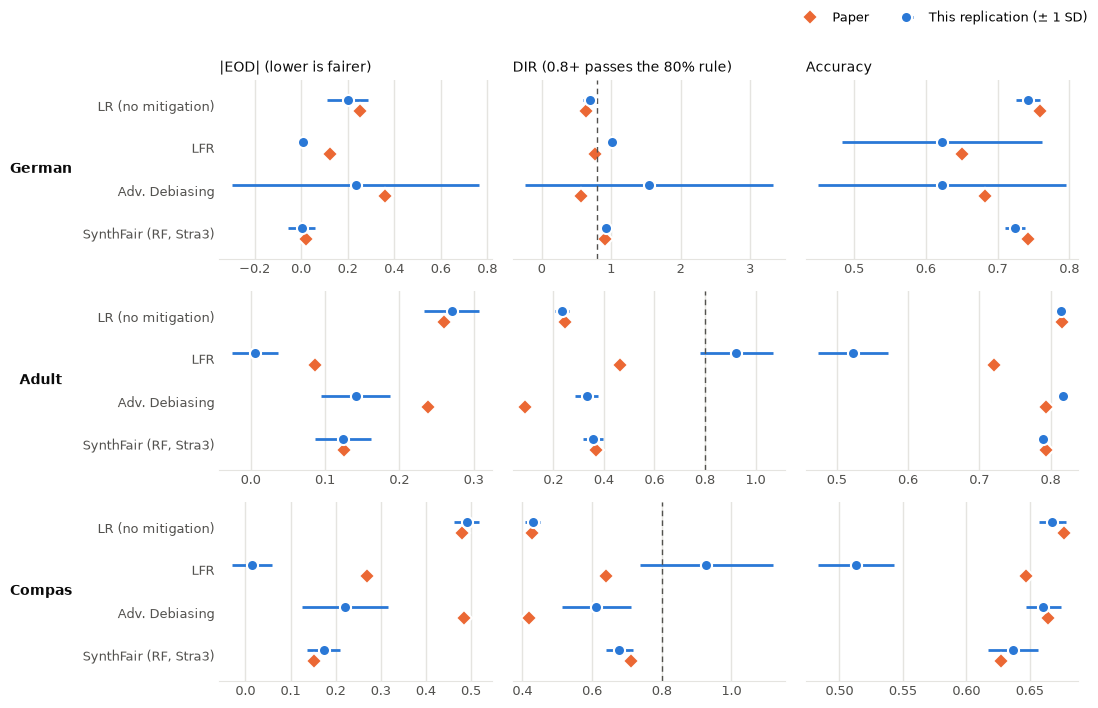

In [15]:
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e5e4e0'
METHODS6 = [('LR','NM','LR (no mitigation)'), ('LR','LFR','LFR'), ('NN','AdvDeb','Adv. Debiasing'), ('RF','Stra3','SynthFair (RF, Stra3)')]
SHOW = ['EOD','DIR','Acc']; NAMES = {'EOD':'|EOD| (lower is fairer)','DIR':'DIR (0.8+ passes the 80% rule)','Acc':'Accuracy'}
present = [d for d in ['german','adult','compas'] if d in data]
fig, axes = plt.subplots(len(present), len(SHOW), figsize=(11, 2.1*len(present)+.8), sharey=True, squeeze=False)
for i, d_ in enumerate(present):
    for j, m in enumerate(SHOW):
        ax = axes[i, j]
        for y_, (c_, me, label) in enumerate(METHODS6[::-1]):
            r = cmp[(cmp.dataset == d_) & (cmp.clf == c_) & (cmp.method == me) & (cmp.metric == m)]
            if r.empty: continue
            r = r.iloc[0]
            ax.errorbar(r.mine, y_+.13, xerr=r.mine_sd, fmt='o', ms=8, color=BLUE, mec='white', mew=1.5, elinewidth=2, capsize=0,
                        label='This replication (± 1 SD)' if (i, j, y_) == (0, 0, 0) else None)
            ax.plot(r.paper, y_-.13, 'D', ms=8, color=ORANGE, mec='white', mew=1.5, label='Paper' if (i, j, y_) == (0, 0, 0) else None)
        ax.set_yticks(range(4)); ax.set_yticklabels([x[2] for x in METHODS6[::-1]], fontsize=9, color=INK)
        ax.set_ylim(-.6, 3.6); ax.grid(axis='x', color=GRID, lw=1); ax.set_axisbelow(True)
        ax.tick_params(axis='both', length=0, labelsize=9, labelcolor=MUTED)
        for s_ in ['top','right','left']: ax.spines[s_].set_visible(False)
        ax.spines['bottom'].set_color(GRID)
        if m == 'DIR': ax.axvline(.8, color=MUTED, lw=1, ls=(0,(4,3)))
        if i == 0: ax.set_title(NAMES[m], fontsize=10, color=INK, loc='left')
    axes[i, 0].set_ylabel(d_.capitalize(), fontsize=10, color=INK, rotation=0, labelpad=30, va='center', fontweight='bold')
fig.legend(*axes[0,0].get_legend_handles_labels(), loc='upper right', ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0,0,1,.94)); fig.savefig(OUT/'comparison_table6.png', dpi=150); plt.show()

### Effect of the test-label leakage

Paired by repetition, so each row uses identical splits and models. `Δ = leaky − clean`. The leak can only change a prediction when some cluster is missing the test row's true cell, so **a Δ of exactly 0 means every cell was present in every cluster**, and the eligibility filter never did anything.

In [16]:
def paired(df, a, b, metrics=('EOD','DIR','Acc','F1')):
    idx = ['dataset','clf','rep']
    x = df[df.method == a].set_index(idx); y = df[df.method == b].set_index(idx)
    d = (x[list(metrics)] - y[list(metrics)]).groupby(level=['dataset','clf'])
    t = d.mean().round(4).astype(str) + ' ± ' + d.std(ddof=1).round(4).astype(str)
    return t.assign(comparison=f'{a} − {b}').set_index('comparison', append=True)
_pairs = [('Stra2','Stra2-noleak'),('Stra3','Stra3-noleak'),('Stra2-group','Stra2-noleak'),('Stra3-group','Stra3-noleak')]
leak = pd.concat([paired(res, a, b) for a, b in _pairs]).sort_index()
leak.to_csv(OUT/'leakage_effect.csv')
leak

EOD               DIR              Acc                F1
dataset clf comparison                                                                                       
adult   LR  Stra2 − Stra2-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
        RF  Stra2 − Stra2-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
compas  LR  Stra2 − Stra2-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
        RF  Stra2 − Stra2-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak               0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
german  GBT Stra2 − Stra2-noleak         0.0143 ± 0.0301   0.0183 ± 0.0387  -0.002 ± 0.0028  -0.0011 ± 0.0016
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak         0.0143 ± 0.0301   0.0184 ± 0.0389  -0.002 ± 0.0028  -0.0011 ± 0.0016
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
        LR  Stra2 − Stra2-noleak        -0.0036 ± 0.0113  -0.0047 ± 0.0149  0.0007 ± 0.0014   0.0004 ± 0.0008
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak        -0.0036 ± 0.0113  -0.0047 ± 0.0149  0.0007 ± 0.0014   0.0004 ± 0.0008
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
        RF  Stra2 − Stra2-noleak         0.0107 ± 0.0241   0.0121 ± 0.0272  -0.002 ± 0.0028  -0.0011 ± 0.0016
            Stra2-group − Stra2-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0
            Stra3 − Stra3-noleak         0.0107 ± 0.0241   0.0121 ± 0.0271  -0.002 ± 0.0028  -0.0011 ± 0.0016
            Stra3-group − Stra3-noleak         0.0 ± 0.0         0.0 ± 0.0        0.0 ± 0.0         0.0 ± 0.0

### Sensitivity runs

1. **Separate test scaling** (what the paper's text says), compared with train-only (what its code does and the default here).
2. **Adult with its natural class distribution**: no undersampling, so `P(y=1) ≈ 0.25` in both train and test. This shows what the undocumented 50/50 step does to the published Adult results.

Paired by repetition where the splits match. LR and RF only, no LFR or AdvDeb.

In [17]:
if EXTRAS:
    sep = pd.concat([run_job(f'separate_{k}', d, scale_mode='separate') for k, d in data.items()], ignore_index=True)
    joined = pd.concat([res[res.scale == 'train_only'], sep], ignore_index=True)
    keep = ['NM','Stra1','Stra2-noleak','Stra3-noleak','Stra3']
    idx = ['dataset','clf','method','rep']
    a = joined[joined.scale == 'separate'].set_index(idx)[['EOD','DIR','Cons','Acc','F1']]
    b = joined[joined.scale == 'train_only'].set_index(idx)[['EOD','DIR','Cons','Acc','F1']]
    d = (a - b).dropna().groupby(level=['dataset','clf','method'])
    scale_effect = (d.mean().round(4).astype(str) + ' ± ' + d.std(ddof=1).round(4).astype(str)).query('method in @keep')
    scale_effect.to_csv(OUT/'scale_effect.csv')
    print('separate − train_only:'); display(scale_effect)

    nat = LOADERS['adult_natural']()
    natural = run_job('natural_adult', nat)
    both = pd.concat([summary.loc[['adult']], summarise(natural)])
    both = pretty(both.loc[both.index.get_level_values('method').isin(['NM','Stra1','Stra3','Stra3-noleak'])])
    display(both)

    nat_adv = run_job('advdeb_adult_natural', nat, adv=True)
    g_ = nat_adv.groupby('method')[['EOD','DIR','Cons','Acc','BalAcc','F1']]
    print('Adversarial Debiasing on Adult with its natural class distribution, against Table 6 (EOD .238, DIR .088, Cons .999, Acc .794, BalAcc .673, F1 .506):')
    display((g_.mean().round(3).astype(str) + ' ± ' + g_.std(ddof=1).round(3).astype(str)))
    print('On the 50/50 data used above:')
    g_ = res[(res.dataset == 'adult') & (res.clf == 'NN')].groupby('method')[['EOD','DIR','Cons','Acc','BalAcc','F1']]
    display((g_.mean().round(3).astype(str) + ' ± ' + g_.std(ddof=1).round(3).astype(str)))

    wb = openpyxl.load_workbook(AUTH/'Tables-Experimental Results.xlsx', data_only=True)['Table3-MainComparison']
    rows_ = [[x for x in r if x is not None] for r in wb.iter_rows(values_only=True)]
    start = next(i for i, r in enumerate(rows_) if r and r[0] == 'Adult')
    print("Authors' main table, Adult, accuracy vs balanced accuracy:")
    display(pd.DataFrame([dict(method=r[0], Acc=r[-3], BalAcc=r[-2], F1=r[-1]) for r in rows_[start+1:start+6]]))

separate_german: cached (160 rows)
separate_adult: cached (160 rows)
separate_compas: cached (160 rows)
separate − train_only:


EOD               DIR              Cons               Acc                F1
dataset clf method                                                                                                
adult   LR  NM             0.0008 ± 0.0028  -0.0002 ± 0.0023  -0.0008 ± 0.0009  -0.0007 ± 0.0009  -0.0008 ± 0.0012
            Stra1           0.0015 ± 0.004   0.0015 ± 0.0086  -0.0007 ± 0.0007  -0.0005 ± 0.0011  -0.0005 ± 0.0023
            Stra2-noleak   0.0011 ± 0.0039    0.003 ± 0.0067    0.0001 ± 0.001  -0.0011 ± 0.0013  -0.0012 ± 0.0014
            Stra3           0.0009 ± 0.008   0.0023 ± 0.0062   0.0001 ± 0.0014  -0.0009 ± 0.0014   -0.001 ± 0.0014
            Stra3-noleak    0.0009 ± 0.008   0.0023 ± 0.0062   0.0001 ± 0.0014  -0.0009 ± 0.0014   -0.001 ± 0.0014
        RF  NM            -0.0005 ± 0.0065  -0.0014 ± 0.0071   -0.0005 ± 0.001  -0.0037 ± 0.0024   -0.004 ± 0.0034
            Stra1          0.0132 ± 0.0229    0.0067 ± 0.008   0.0015 ± 0.0056  -0.0049 ± 0.0034  -0.0074 ± 0.0067
            Stra2-noleak   0.0227 ± 0.0243   0.0126 ± 0.0218   0.0002 ± 0.0027  -0.0051 ± 0.0044  -0.0079 ± 0.0074
            Stra3           0.024 ± 0.0264    0.014 ± 0.0222   0.0004 ± 0.0024  -0.0053 ± 0.0045   -0.008 ± 0.0076
            Stra3-noleak    0.024 ± 0.0264    0.014 ± 0.0222   0.0004 ± 0.0024  -0.0053 ± 0.0045   -0.008 ± 0.0076
compas  LR  NM            -0.0055 ± 0.0177  -0.0089 ± 0.0188   0.0005 ± 0.0009   0.0004 ± 0.0038   -0.002 ± 0.0034
            Stra1           0.003 ± 0.0074  -0.0007 ± 0.0022  -0.0008 ± 0.0011  -0.0005 ± 0.0022  -0.0026 ± 0.0064
            Stra2-noleak   -0.0022 ± 0.014  -0.0137 ± 0.0258   0.0003 ± 0.0012  -0.0005 ± 0.0029  -0.0061 ± 0.0096
            Stra3          -0.0021 ± 0.014  -0.0139 ± 0.0264    0.0002 ± 0.001  -0.0003 ± 0.0027   -0.006 ± 0.0099
            Stra3-noleak   -0.0021 ± 0.014  -0.0139 ± 0.0264    0.0002 ± 0.001  -0.0003 ± 0.0027   -0.006 ± 0.0099
        RF  NM             0.0095 ± 0.0246   0.0073 ± 0.0148    0.0004 ± 0.003   -0.002 ± 0.0055  -0.0022 ± 0.0047
            Stra1          0.0262 ± 0.0338    0.051 ± 0.0643  -0.0078 ± 0.0088  -0.0399 ± 0.0191  -0.0364 ± 0.0135
            Stra2-noleak   0.0359 ± 0.0357   0.0663 ± 0.0568  -0.0073 ± 0.0092   -0.0391 ± 0.018  -0.0321 ± 0.0186
            Stra3          0.0354 ± 0.0339    0.065 ± 0.0554  -0.0073 ± 0.0092  -0.0388 ± 0.0177  -0.0325 ± 0.0182
            Stra3-noleak   0.0354 ± 0.0339    0.065 ± 0.0554  -0.0073 ± 0.0092  -0.0388 ± 0.0177  -0.0325 ± 0.0182
german  LR  NM            -0.0124 ± 0.0313  -0.0196 ± 0.0313  -0.0111 ± 0.0152   -0.002 ± 0.0101   -0.0038 ± 0.008
            Stra1         -0.0205 ± 0.0518  -0.0383 ± 0.0859  -0.0008 ± 0.0158  -0.0067 ± 0.0113  -0.0101 ± 0.0143
            Stra2-noleak  -0.0168 ± 0.0362  -0.0262 ± 0.0532  -0.0034 ± 0.0095  -0.0007 ± 0.0089  -0.0025 ± 0.0103
            Stra3         -0.0095 ± 0.0428  -0.0119 ± 0.0622  -0.0031 ± 0.0064    -0.004 ± 0.011  -0.0054 ± 0.0097
            Stra3-noleak  -0.0095 ± 0.0428  -0.0117 ± 0.0622   -0.003 ± 0.0063    -0.004 ± 0.011  -0.0054 ± 0.0097
        RF  NM             0.0038 ± 0.0391   0.0013 ± 0.0411   0.0007 ± 0.0155   -0.002 ± 0.0053  -0.0019 ± 0.0035
            Stra1          0.0174 ± 0.0539     0.02 ± 0.0627  -0.0047 ± 0.0124   -0.004 ± 0.0075  -0.0038 ± 0.0062
            Stra2-noleak  -0.0225 ± 0.0366    -0.0324 ± 0.05  -0.0023 ± 0.0106   -0.001 ± 0.0131   -0.0027 ± 0.011
            Stra3         -0.0193 ± 0.0339    -0.03 ± 0.0444  -0.0033 ± 0.0099  -0.0013 ± 0.0144  -0.0028 ± 0.0117
            Stra3-noleak  -0.0229 ± 0.0347  -0.0343 ± 0.0457  -0.0034 ± 0.0098  -0.0007 ± 0.0149  -0.0024 ± 0.0119

natural_adult: cached (160 rows)


|EOD| mean|EOD|            DIR           Cons            Acc             F1
dataset       clf method                                                                                           
adult         LR  NM            0.271 ± 0.037     0.271  0.235 ± 0.028  0.934 ± 0.003  0.815 ± 0.006  0.821 ± 0.006
                  Stra1         0.032 ± 0.028     0.037  0.502 ± 0.062  0.875 ± 0.006  0.743 ± 0.010  0.729 ± 0.015
                  Stra3         0.030 ± 0.052     0.053  0.520 ± 0.068  0.879 ± 0.007  0.731 ± 0.008  0.727 ± 0.009
                  Stra3-noleak  0.030 ± 0.052     0.053  0.520 ± 0.068  0.879 ± 0.007  0.731 ± 0.008  0.727 ± 0.009
              RF  NM            0.200 ± 0.050     0.200  0.273 ± 0.046  0.857 ± 0.004  0.808 ± 0.004  0.810 ± 0.004
                  Stra1         0.134 ± 0.044     0.134  0.338 ± 0.040  0.830 ± 0.006  0.791 ± 0.008  0.789 ± 0.009
                  Stra3         0.124 ± 0.038     0.124  0.357 ± 0.038  0.833 ± 0.005  0.790 ± 0.008  0.789 ± 0.008
                  Stra3-noleak  0.124 ± 0.038     0.124  0.357 ± 0.038  0.833 ± 0.005  0.790 ± 0.008  0.789 ± 0.008
adult_natural LR  NM            0.155 ± 0.032     0.155  0.160 ± 0.017  0.949 ± 0.002  0.845 ± 0.003  0.656 ± 0.007
                  Stra1         0.062 ± 0.033     0.062  0.428 ± 0.047  0.900 ± 0.005  0.778 ± 0.007  0.621 ± 0.011
                  Stra3         0.051 ± 0.037     0.058  0.439 ± 0.043  0.899 ± 0.004  0.777 ± 0.006  0.619 ± 0.009
                  Stra3-noleak  0.047 ± 0.034     0.055  0.441 ± 0.042  0.899 ± 0.004  0.777 ± 0.006  0.619 ± 0.009
              RF  NM            0.139 ± 0.026     0.139  0.179 ± 0.017  0.885 ± 0.002  0.842 ± 0.003  0.662 ± 0.008
                  Stra1         0.105 ± 0.024     0.105  0.244 ± 0.027  0.872 ± 0.003  0.831 ± 0.003  0.652 ± 0.008
                  Stra3         0.111 ± 0.038     0.111  0.235 ± 0.024  0.875 ± 0.004  0.830 ± 0.004  0.645 ± 0.009
                  Stra3-noleak  0.113 ± 0.037     0.113  0.234 ± 0.023  0.875 ± 0.004  0.830 ± 0.004  0.645 ± 0.009

advdeb_adult_natural: cached (20 rows)
Adversarial Debiasing on Adult with its natural class distribution, against Table 6 (EOD .238, DIR .088, Cons .999, Acc .794, BalAcc .673, F1 .506):


,EOD,DIR,Cons,Acc,BalAcc,F1
method,,,,,,
AdvDeb,-0.023 ± 0.038,0.284 ± 0.035,0.937 ± 0.003,0.848 ± 0.003,0.76 ± 0.007,0.657 ± 0.009
AdvDeb-priv11,0.073 ± 0.042,0.447 ± 0.062,0.937 ± 0.003,0.836 ± 0.004,0.728 ± 0.009,0.608 ± 0.014


On the 50/50 data used above:


,EOD,DIR,Cons,Acc,BalAcc,F1
method,,,,,,
AdvDeb,-0.142 ± 0.047,0.333 ± 0.046,0.911 ± 0.004,0.817 ± 0.004,0.817 ± 0.004,0.82 ± 0.006
AdvDeb-priv11,-0.03 ± 0.062,0.422 ± 0.083,0.902 ± 0.003,0.801 ± 0.007,0.801 ± 0.007,0.795 ± 0.009


Authors' main table, Adult, accuracy vs balanced accuracy:


,method,Acc,BalAcc,F1
0,LR,0.815985,0.815981,0.821362
1,LFR,0.719554,0.688053,0.520178
2,Adv Deb,0.793530,0.673058,0.505821
3,COSCFairLR,0.769472,0.769475,0.765615
4,COSCFair,0.793844,0.793844,0.792519


### "Original DF" row and the Table 5 check

"Original DF" in Table 6 is the true labels, whole dataset. The repo computes consistency on aif360's unscaled features, so it is shown both ways. For Adult, Table 6's DIR only fits the distribution before undersampling.

In [18]:
ORIG = {'german': (.748,.682), 'adult': (.235,.848), 'compas': (.688,.675)}
rows = []
for k, d in data.items():
    for label, f in [('all rows before balancing', d.natural), ('rows used in experiments', d.frame)]:
        if label.startswith('all') is False and len(d.natural) == len(d.frame): continue
        u, p = f[(f.a1==0)&(f.a2==0)].y.mean(), f[(f.a1==1)&(f.a2==1)].y.mean()
        X = f[d.features + ['a1','a2']].astype(float)
        Xs = X.copy(); Xs[d.num_cols] = MinMaxScaler().fit_transform(Xs[d.num_cols])
        rows.append(dict(dataset=k, data=label, DIR=u/p, Cons_raw=consistency(X.values, f.y.values), Cons_scaled=consistency(Xs.values, f.y.values),
                         paper_DIR=ORIG.get(k,(np.nan,))[0], paper_Cons=ORIG.get(k,(np.nan,np.nan))[1]))
pd.DataFrame(rows).round(3)

,dataset,data,DIR,Cons_raw,Cons_scaled,paper_DIR,paper_Cons
0,german,all rows before balancing,0.748,0.682,0.747,0.748,0.682
1,adult,all rows before balancing,0.230,0.845,0.827,0.235,0.848
2,adult,rows used in experiments,0.323,0.809,0.793,0.235,0.848
3,compas,all rows before balancing,0.687,0.604,0.601,0.688,0.675
